# T02 · Data Preprocessing (Missing · Outlier · Encoding · Scaling · Discretization · Sampling · Split ไม่ leak · Feature selection)

**ใช้เมื่อโจทย์ถาม:** จัดการค่าว่าง · ค่าแฝง (`?`, 0 ที่เป็นไปไม่ได้) · outlier · one-hot / ordinal / label encoding ·
z-score / min-max · แบ่งช่วง (equal width / equal frequency / กำหนดเอง) · สุ่มตัวอย่าง / stratified ·
แบ่ง train/test **โดยไม่ leak** · เลือก feature · "เปรียบเทียบก่อน/หลัง preprocessing"

> SMOTE / undersampling แบบเต็ม → **T04** · PCA → **T03**

| ขั้น | ทำอะไร |
|---|---|
| 1 | แก้ **⚙️ CONFIG** · Run All |
| 2 | ไป § ที่โจทย์ถาม → แก้บรรทัด `# ✏️` → รันใหม่ |
| 3 | §1–§7 = **สำรวจ/สาธิต** (ทำกับทั้งตาราง เพื่อดูผล) · §8 = วิธีที่ **ถูกต้องตอนสร้างโมเดล** (fit บน train เท่านั้น) |

In [1]:
# ════════ ⚙️ CONFIG — แก้ cell นี้ให้ตรงโจทย์ ════════
DATA_PATH = "../practice/data/p2_penguins.csv"
TARGET    = "species"        # label (ไม่มีใส่ None)
POS_LABEL = None             # ถ้า target มี 2 คลาส: คลาสที่สนใจ (เช่น "Yes", 1, ">50K") · None = เลือกตัวท้ายตามตัวอักษร
ID_COL    = None             # คอลัมน์ id
DROP_COLS = []               # คอลัมน์ที่ตัดทิ้งแน่นอน (leak / ไม่เกี่ยว)
MISSING_MARKERS = ["?", "", " ", "NA", "N/A", "null", "-"]
ZERO_AS_MISSING = []         # คอลัมน์ที่ค่า 0 เป็นไปไม่ได้ = ค่าว่าง (เช่น pima: ["glucose", "bmi", "blood_pressure"])
SCALE     = "standard"       # "standard" (z-score) | "minmax" (0–1) | None
TEST_SIZE = 0.2
SEED      = 42
N_FOLDS   = 5
SHEET, CSV_SEP = 0, ","

In [2]:
# ════════ 🔧 IMPORTS + HELPERS — ไม่ต้องแก้ cell นี้ แค่รันหลัง CONFIG ════════
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer, LabelEncoder)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, silhouette_samples, davies_bouldin_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ค่า default ถ้า CONFIG ไม่ได้กำหนดไว้ (กันลืม)
for _name, _val in {"SEED": 42, "N_FOLDS": 5, "TEST_SIZE": 0.2, "TARGET": None, "POS_LABEL": None,
                    "ID_COL": None, "DROP_COLS": [], "MISSING_MARKERS": ["?", "", " ", "NA", "N/A", "null"],
                    "SHEET": 0, "CSV_SEP": ",", "SCALE": "standard"}.items():
    globals().setdefault(_name, _val)


def load_data(path, sheet=None, sep=None, na_values=None):
    """อ่าน .csv / .xlsx / .xls → ตัดช่องว่างหัวคอลัมน์และค่า string → แปลงค่าแฝง ('?', '') เป็น NaN"""
    sheet = SHEET if sheet is None else sheet
    sep = CSV_SEP if sep is None else sep
    na_values = MISSING_MARKERS if na_values is None else na_values
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=sheet)
    else:
        df = pd.read_csv(path, sep=sep)
    df.columns = [str(c).strip() for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df = df.replace(list(na_values), np.nan)
    # คอลัมน์ที่เป็นตัวเลขแต่ถูกอ่านเป็น text (เพราะเคยมี '?') → แปลงกลับเป็นตัวเลข
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() == df[c].notna().sum() and df[c].notna().any():
                df[c] = conv
    print(f"โหลด {path} → {df.shape[0]} แถว × {df.shape[1]} คอลัมน์")
    return df


def check(df, target=None):
    """ตรวจข้อมูลใน 1 คำสั่ง: ขนาด · ชนิด · ค่าว่าง · unique · ตัวอย่างค่า · สัดส่วน target"""
    print("shape:", df.shape, "| แถวซ้ำ:", int(df.duplicated().sum()))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "unique": df.nunique(),
                         "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df]})
    display(info)
    if target is not None and target in df and pd.api.types.is_numeric_dtype(df[target]) and df[target].nunique() > 15:
        print(f"target '{target}' เป็นตัวเลข (regression):")
        display(df[target].describe().to_frame().T)
    elif target is not None and target in df:
        vc = pd.concat([df[target].value_counts(dropna=False), df[target].value_counts(normalize=True, dropna=False).round(4)],
                       axis=1, keys=["count", "ratio"])
        print(f"การกระจายของ target '{target}':")
        display(vc)


def num_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def cat_cols(df):
    return [c for c in df.columns if c not in num_cols(df)]


def make_xy(df, target=None, drop=None, pos_label=None, task="classification"):
    """แยก X / y · ตัด target + DROP_COLS + ID_COL · classification 2 คลาส → y = 1 ถ้าเท่ากับ POS_LABEL"""
    target = TARGET if target is None else target
    drop = DROP_COLS if drop is None else drop
    pos_label = POS_LABEL if pos_label is None else pos_label
    d = df.dropna(subset=[target]).copy()
    removed = [c for c in list(drop) + [ID_COL] if c is not None and c in d.columns and c != target]
    X = d.drop(columns=[target] + removed)
    if task == "regression":
        y = d[target].astype(float)
        print(f"X: {X.shape} | y = '{target}' (ตัวเลข) | ตัดคอลัมน์: {removed}")
        return X, y
    raw = d[target]
    classes = sorted(raw.astype(str).unique())
    if len(classes) == 2:
        pos = str(pos_label) if pos_label is not None else classes[-1]
        if pos not in classes:
            raise ValueError(f"POS_LABEL={pos_label!r} ไม่อยู่ใน {classes} — แก้ใน CONFIG")
        neg = [c for c in classes if c != pos][0]
        y = (raw.astype(str) == pos).astype(int).rename(target)
        print(f"X: {X.shape} | y = '{target}' → 1 = {pos!r} (positive), 0 = {neg!r} | ตัดคอลัมน์: {removed}")
    else:
        y = raw.astype(str)
        print(f"X: {X.shape} | y = '{target}' มี {len(classes)} คลาส {classes} (multiclass → ใช้ macro avg) | ตัดคอลัมน์: {removed}")
    return X, y


def is_binary(y):
    return pd.Series(y).nunique() == 2


def build_prep(X, scale="config", num_impute="median", onehot=True):
    """preprocessing ที่ fit เฉพาะ train (ใส่ใน Pipeline → ไม่ leak)
    ตัวเลข: เติมค่าว่าง (median) → scale ('standard' z-score | 'minmax' 0–1 | None)
    หมวดหมู่: เติมค่าว่าง (ค่าที่พบบ่อยสุด) → one-hot"""
    if scale == "config":                      # ไม่ระบุ → ใช้ SCALE จาก CONFIG · ส่ง None = ไม่ scale
        scale = SCALE
    nums, cats = num_cols(X), cat_cols(X)
    scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(scale, "passthrough")
    num_pipe = Pipeline([("impute", SimpleImputer(strategy=num_impute)), ("scale", scaler)])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else \
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)])
    return ColumnTransformer([("num", num_pipe, nums), ("cat", cat_pipe, cats)],
                             verbose_feature_names_out=False)


def make_pipe(model, X, scale="config", **kw):
    """Pipeline = preprocessing (fit บน train fold เท่านั้น) + model"""
    return Pipeline([("prep", build_prep(X, scale=scale, **kw)), ("model", model)])


def get_cv(task="classification", n=None):
    n = N_FOLDS if n is None else n
    if task == "regression":
        return KFold(n_splits=n, shuffle=True, random_state=SEED)
    return StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED)


def cls_scoring(y):
    if is_binary(y):
        return {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
    return {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}


def evaluate(name, model, X, y, cv=None, settings="", train=False):
    """classification ด้วย cross-validation → 1 แถว (ค่าเฉลี่ยทุก fold) ใช้ต่อเป็นตารางเปรียบเทียบ"""
    cv = get_cv() if cv is None else cv
    r = cross_validate(model, X, y, cv=cv, scoring=cls_scoring(y), return_train_score=train)
    row = {"model": name, "settings": settings}
    row.update({m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]})
    row["f1_std"] = r["test_f1"].std()
    if train:
        row["train_accuracy"] = r["train_accuracy"].mean()
    return row


def evaluate_holdout(name, model, X_tr, y_tr, X_te, y_te, settings=""):
    """classification แบบ hold-out: fit บน train → วัดบน test"""
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    avg = "binary" if is_binary(y_tr) else "macro"
    return {"model": name, "settings": settings,
            "accuracy": accuracy_score(y_te, p),
            "precision": precision_score(y_te, p, average=avg, zero_division=0),
            "recall": recall_score(y_te, p, average=avg, zero_division=0),
            "f1": f1_score(y_te, p, average=avg, zero_division=0),
            "train_accuracy": accuracy_score(y_tr, model.predict(X_tr))}


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse),
            "R2": r2_score(y_true, y_pred)}


def evaluate_reg(name, model, X, y, cv=None, settings=""):
    """regression ด้วย cross-validation → MAE / MSE / RMSE / R²"""
    cv = get_cv("regression") if cv is None else cv
    r = cross_validate(model, X, y, cv=cv,
                       scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    mse = -r["test_neg_mean_squared_error"].mean()
    return {"model": name, "settings": settings, "MAE": -r["test_neg_mean_absolute_error"].mean(),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r["test_r2"].mean()}


def show_cm(y_true, y_pred, title="Confusion matrix"):
    """confusion matrix (แถว = actual, คอลัมน์ = predicted) + classification report"""
    labels = sorted(pd.Series(y_true).unique(), key=str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"pred {l}" for l in labels]))
    if len(labels) == 2:
        tn, fp, fn, tp = cm.ravel()
        print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); ax.grid(False); plt.show()
    return cm


def top_k(grid, n=10):
    """ตารางผล GridSearchCV เรียงจากดีสุด"""
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res if c.startswith("param_")] + \
           [c for c in res if c.startswith("mean_test_") or c.startswith("mean_train_")]
    key = f"mean_test_{grid.refit}" if isinstance(grid.refit, str) else "mean_test_score"
    return res[cols].sort_values(key, ascending=False).head(n).reset_index(drop=True)


def results_table(rows, sort_by=None, ascending=False):
    t = pd.DataFrame(rows)
    if sort_by:
        t = t.sort_values(sort_by, ascending=ascending)
    display(t.reset_index(drop=True))
    return t.reset_index(drop=True)


def say_compare(table, metric="f1", baseline_name=None, higher_is_better=True):
    """พิมพ์ประโยคตีความสำเร็จรูปจากตารางผล (copy ไปใส่คำตอบได้เลย)"""
    t = table.sort_values(metric, ascending=not higher_is_better)
    best = t.iloc[0]
    msg = f"✍️ โมเดลที่ดีที่สุดตาม {metric} คือ {best['model']}"
    if str(best.get("settings", "")):
        msg += f" ({best['settings']})"
    msg += f" ได้ {metric} = {best[metric]:.4f}"
    if baseline_name is not None and baseline_name in set(table["model"]):
        b = table.loc[table["model"] == baseline_name].iloc[0]
        diff = best[metric] - b[metric]
        msg += f" เทียบกับ baseline ({baseline_name}) ที่ได้ {b[metric]:.4f} ต่างกัน {diff:+.4f}"
        if "accuracy" in table and metric != "accuracy":
            msg += f" (baseline accuracy = {b['accuracy']:.4f} แต่ {metric} ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)"
    print(msg)


def new_data(source):
    """ข้อมูลใหม่ที่จะทำนาย: path ไฟล์ (str) / dict 1 แถว / list ของ dict / DataFrame"""
    if source is None:
        return None
    if isinstance(source, str):
        return load_data(source)
    if isinstance(source, dict):
        return pd.DataFrame([source])
    if isinstance(source, list):
        return pd.DataFrame(source)
    return source.copy()


def align_new(df_new, X_ref):
    """จัดคอลัมน์ข้อมูลใหม่ให้ตรงกับ X ที่ใช้ train (คอลัมน์ที่ขาดเติม NaN → imputer จัดการ)"""
    missing = [c for c in X_ref.columns if c not in df_new.columns]
    if missing:
        print("⚠️ ข้อมูลใหม่ขาดคอลัมน์:", missing, "→ เติม NaN (imputer จะเติมให้)")
    return df_new.reindex(columns=X_ref.columns)

print("✅ helpers พร้อม | SEED =", SEED, "| N_FOLDS =", N_FOLDS)

✅ helpers พร้อม | SEED = 42 | N_FOLDS = 5


## §1 โหลด + สำรวจค่าว่าง (รันเสมอ)

โหลด ../practice/data/p2_penguins.csv → 344 แถว × 7 คอลัมน์
shape: (344, 7) | แถวซ้ำ: 0


,dtype,missing,missing_%,unique,example
species,str,0,0.0000,3,Adelie
island,str,0,0.0000,3,Torgersen
bill_length_mm,float64,2,0.5800,164,39.1000
bill_depth_mm,float64,2,0.5800,80,18.7000
flipper_length_mm,float64,2,0.5800,55,181.0000
body_mass_g,float64,2,0.5800,94,"3,750.0000"
sex,str,11,3.2000,2,MALE


การกระจายของ target 'species':


,count,ratio
species,,
Adelie,152,0.4419
Gentoo,124,0.3605
Chinstrap,68,0.1977


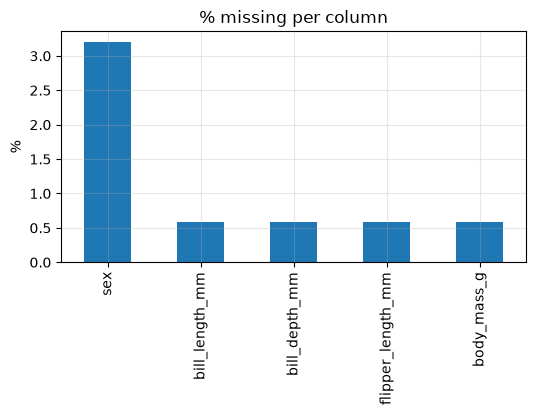

แถวที่มีค่าว่างอย่างน้อย 1 ช่อง: 11 / 344


In [3]:
df = load_data(DATA_PATH)
for c in ZERO_AS_MISSING:
    n0 = int((df[c] == 0).sum()); df[c] = df[c].replace(0, np.nan)
    print(f"{c}: 0 → NaN จำนวน {n0} ค่า (ค่า 0 เป็นไปไม่ได้ทางความหมาย)")
check(df, TARGET)
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
if len(miss):
    (miss / len(df) * 100).plot(kind="bar", figsize=(6, 3), title="% missing per column"); plt.ylabel("%"); plt.show()
print(f"แถวที่มีค่าว่างอย่างน้อย 1 ช่อง: {int(df.isna().any(axis=1).sum())} / {len(df)}")

**✍️ คำตอบ §1:** มีค่าว่างใน … (… ค่า, …%) · ค่าแฝง `?`/0 ที่เป็นไปไม่ได้ใน … ถูกแปลงเป็น missing ก่อน

## §2 Missing-value handling — เลือกวิธี
| วิธี | ใช้เมื่อ | ข้อเสีย |
|---|---|---|
| ลบแถว (`dropna`) | ค่าว่างน้อยมาก (< ~5%) | เสียข้อมูล · bias ถ้าว่างไม่สุ่ม |
| ลบคอลัมน์ | คอลัมน์ว่าง > ~40–50% | เสียตัวแปร |
| mean | ตัวเลข สมมาตร ไม่มี outlier | โดน outlier ดึง |
| **median** | ตัวเลข เบ้ / มี outlier | — |
| mode (ค่าที่พบบ่อย) | หมวดหมู่ | คลาสนั้นพองขึ้น |
| ค่าคงที่ / "Unknown" | ความว่างมีความหมาย | — |
| ตามกลุ่ม (group median) | ค่าต่างกันตามกลุ่มชัดเจน | ต้องรู้กลุ่ม |

In [4]:
MISS_METHOD = "median"     # ✏️ "drop_rows" | "drop_cols" | "mean" | "median" | "mode" | "constant" | "group"
DROP_COL_THRESHOLD = 0.5   # ✏️ ใช้กับ drop_cols: ตัดคอลัมน์ที่ว่างเกินสัดส่วนนี้
CONSTANT = "Unknown"       # ✏️ ใช้กับ constant (หมวดหมู่) — ตัวเลขจะเติม 0
GROUP_COL = TARGET         # ✏️ ใช้กับ group: เติม median/mode ตามกลุ่มนี้

clean = df.copy()
before = int(clean.isna().sum().sum())
if MISS_METHOD == "drop_rows":
    clean = clean.dropna()
elif MISS_METHOD == "drop_cols":
    clean = clean.loc[:, clean.isna().mean() <= DROP_COL_THRESHOLD]
else:
    for c in clean.columns[clean.isna().any()]:
        is_num = c in num_cols(clean)
        if MISS_METHOD == "group" and GROUP_COL and c != GROUP_COL:
            fill = clean.groupby(GROUP_COL)[c].transform(lambda s: s.median() if is_num else (s.mode().iloc[0] if s.notna().any() else np.nan))
            clean[c] = clean[c].fillna(fill)
        elif MISS_METHOD == "constant":
            clean[c] = clean[c].fillna(0 if is_num else CONSTANT)
        elif is_num and MISS_METHOD in ("mean", "median"):
            v = clean[c].mean() if MISS_METHOD == "mean" else clean[c].median()
            print(f"{c}: เติม {MISS_METHOD} = {v:.4f}"); clean[c] = clean[c].fillna(v)
        else:                                  # หมวดหมู่ หรือ mode
            v = clean[c].mode().iloc[0]; print(f"{c}: เติม mode = {v!r}"); clean[c] = clean[c].fillna(v)
print(f"วิธี {MISS_METHOD}: missing ทั้งหมด {before} → {int(clean.isna().sum().sum())} | shape {df.shape} → {clean.shape}")
display(clean.describe().T)

bill_length_mm: เติม median = 44.4500
bill_depth_mm: เติม median = 17.3000
flipper_length_mm: เติม median = 197.0000
body_mass_g: เติม median = 4050.0000
sex: เติม mode = 'MALE'
วิธี median: missing ทั้งหมด 19 → 0 | shape (344, 7) → (344, 7)


,count,mean,std,min,25%,50%,75%,max
bill_length_mm,344.0000,43.9250,5.4438,32.1000,39.2750,44.4500,48.5000,59.6000
bill_depth_mm,344.0000,17.1520,1.9691,13.1000,15.6000,17.3000,18.7000,21.5000
flipper_length_mm,344.0000,200.8924,14.0238,172.0000,190.0000,197.0000,213.0000,231.0000
body_mass_g,344.0000,"4,200.8721",799.6965,"2,700.0000","3,550.0000","4,050.0000","4,750.0000","6,300.0000"


**✍️ คำตอบ §2:** เลือก … เพราะ … (เช่น `…` เบ้ขวา/มี outlier → median ทนกว่า mean · หมวดหมู่ใช้ mode) · ค่าว่างลดจาก … เป็น 0 · ⚠️ ตอนสร้างโมเดลต้องคำนวณค่าที่เติมจาก **train เท่านั้น** (§8)

## §3 Outliers (IQR rule: < Q1 − 1.5·IQR หรือ > Q3 + 1.5·IQR)

,column,Q1,Q3,IQR,lower,upper,n_outliers
0,bill_length_mm,39.2750,48.5000,9.2250,25.4375,62.3375,0
1,bill_depth_mm,15.6000,18.7000,3.1000,10.9500,23.3500,0
2,flipper_length_mm,190.0000,213.0000,23.0000,155.5000,247.5000,0
3,body_mass_g,"3,550.0000","4,750.0000","1,200.0000","1,750.0000","6,550.0000",0


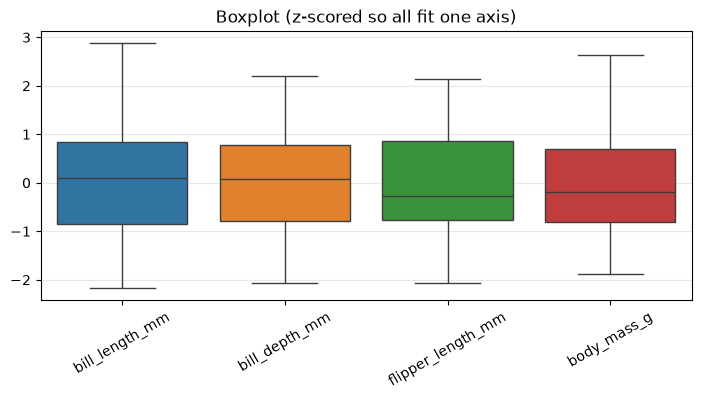

In [5]:
OUT_METHOD = None     # ✏️ None = แค่นับ · "clip" = ตัดให้อยู่ในขอบ (winsorize) · "remove" = ลบแถว

cols = [c for c in num_cols(clean) if c not in (TARGET, ID_COL)]
rows = []
for c in cols:
    q1, q3 = clean[c].quantile([.25, .75]); iqr = q3 - q1; lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((clean[c] < lo) | (clean[c] > hi)).sum())
    rows.append({"column": c, "Q1": q1, "Q3": q3, "IQR": iqr, "lower": lo, "upper": hi, "n_outliers": n})
    if OUT_METHOD == "clip":
        clean[c] = clean[c].clip(lo, hi)
    elif OUT_METHOD == "remove":
        clean = clean[(clean[c] >= lo) & (clean[c] <= hi)]
display(pd.DataFrame(rows))
zs = (clean[cols] - clean[cols].mean()) / clean[cols].std()
fig, ax = plt.subplots(figsize=(min(14, 1.6 * len(cols) + 2), 3.5))
sns.boxplot(data=zs, ax=ax); ax.set_title("Boxplot (z-scored so all fit one axis)"); plt.xticks(rotation=30); plt.show()

## §4 Encoding categorical attributes
| วิธี | ใช้กับ | ตัวอย่าง |
|---|---|---|
| **One-hot (dummy)** | nominal ไม่มีลำดับ | island → island_Biscoe, island_Dream, … |
| **Ordinal / mapping** | มีลำดับ | low < mid < high → 0,1,2 |
| **Binary map** | 2 ค่า | Yes/No → 1/0 |
| **Label encoding** | **target** เท่านั้น | species → 0,1,2 |

In [6]:
ORDINAL_MAP = {}                       # ✏️ เช่น {"education": ["low", "mid", "high"]} (เรียงจากน้อยไปมาก)
BINARY_MAP  = {}                       # ✏️ เช่น {"smoker": {"yes": 1, "no": 0}}
DROP_FIRST  = False                    # ✏️ True = ตัด dummy ตัวแรก (กัน multicollinearity ใน linear/logistic regression)

enc = clean.copy()
for c, order in ORDINAL_MAP.items():
    enc[c] = enc[c].map({v: i for i, v in enumerate(order)}); print(f"ordinal {c}: {order} → 0..{len(order)-1}")
for c, m in BINARY_MAP.items():
    enc[c] = enc[c].map(m); print(f"binary {c}: {m}")
onehot_cols = [c for c in cat_cols(enc) if c not in (TARGET, ID_COL)]
enc = pd.get_dummies(enc, columns=onehot_cols, drop_first=DROP_FIRST, dtype=int)
print("one-hot:", onehot_cols, f"→ คอลัมน์ {clean.shape[1]} → {enc.shape[1]}")
if TARGET and TARGET in enc and not pd.api.types.is_numeric_dtype(enc[TARGET]):
    le = LabelEncoder().fit(enc[TARGET])
    print("label encoding ของ target:", {k: int(v) for k, v in zip(le.classes_, le.transform(le.classes_))})
display(enc.head())

one-hot: ['island', 'sex'] → คอลัมน์ 7 → 10
label encoding ของ target: {'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2}


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Biscoe,island_Dream,island_Torgersen,sex_FEMALE,sex_MALE
0,Adelie,39.1000,18.7000,181.0000,"3,750.0000",0,0,1,0,1
1,Adelie,39.5000,17.4000,186.0000,"3,800.0000",0,0,1,1,0
2,Adelie,40.3000,18.0000,195.0000,"3,250.0000",0,0,1,1,0
3,Adelie,44.4500,17.3000,197.0000,"4,050.0000",0,0,1,0,1
4,Adelie,36.7000,19.3000,193.0000,"3,450.0000",0,0,1,1,0


**✍️ คำตอบ §4:** `…` เป็น nominal (ไม่มีลำดับ) → one-hot เพื่อไม่ให้โมเดลคิดว่า A < B · `…` มีลำดับ → ordinal · ได้ … คอลัมน์

## §5 Standardization vs Normalization
- **z-score (standardization)** $z = (x-\bar x)/s$ → mean 0, std 1 · ทนกับ outlier มากกว่า · ใช้กับ KNN, K-Means, PCA, logistic
- **min-max (normalization)** $x' = (x-\min)/(\max-\min)$ → อยู่ใน [0, 1] · ถูก outlier บีบ
- โมเดลที่ใช้ **ระยะทาง** (KNN, K-Means) และ PCA **ต้อง** scale · Tree/RF **ไม่ต้อง**
- sklearn หาร $n$ · RapidMiner หาร $n-1$ (ตัวเลขต่างเล็กน้อย — ไม่ผิด)

bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
original mean         43.9250        17.1520           200.8924   4,200.8721
         std           5.4438         1.9691            14.0238     799.6965
         min          32.1000        13.1000           172.0000   2,700.0000
         max          59.6000        21.5000           231.0000   6,300.0000
z-score  mean         -0.0000         0.0000             0.0000       0.0000
         std           1.0015         1.0015             1.0015       1.0015
         min          -2.1754        -2.0609            -2.0632      -1.8795
         max           2.8836         2.2114             2.1500       2.6287
min-max  mean          0.4300         0.4824             0.4897       0.4169
         std           0.1980         0.2344             0.2377       0.2221
         min           0.0000         0.0000             0.0000       0.0000
         max           1.0000         1.0000             1.0000       1.0000

ตัวอย่าง 3 แถวแรก (z-score):


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.8876,0.7873,-1.4205,-0.5646
1,-0.8140,0.1261,-1.0635,-0.5020
2,-0.6669,0.4313,-0.4208,-1.1908


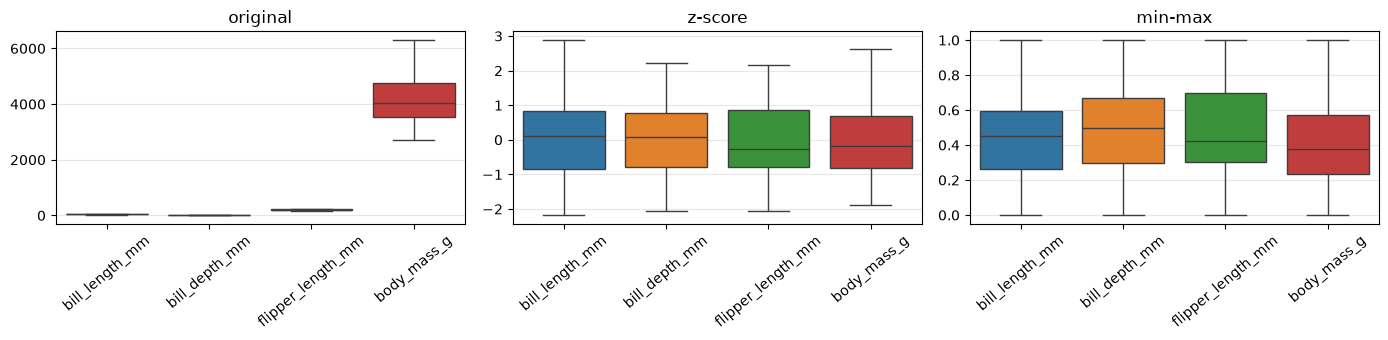

In [7]:
cols = [c for c in num_cols(clean) if c not in (TARGET, ID_COL)]
Z = pd.DataFrame(StandardScaler().fit_transform(clean[cols]), columns=cols, index=clean.index)
M = pd.DataFrame(MinMaxScaler().fit_transform(clean[cols]), columns=cols, index=clean.index)
Z_rm = (clean[cols] - clean[cols].mean()) / clean[cols].std(ddof=1)        # แบบ RapidMiner (n−1)
summary = pd.concat({"original": clean[cols].agg(["mean", "std", "min", "max"]),
                     "z-score": Z.agg(["mean", "std", "min", "max"]),
                     "min-max": M.agg(["mean", "std", "min", "max"])})
display(summary.round(4))
print("ตัวอย่าง 3 แถวแรก (z-score):"); display(Z.head(3))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, (name, d) in zip(ax, [("original", clean[cols]), ("z-score", Z), ("min-max", M)]):
    sns.boxplot(data=d, ax=a); a.set_title(name); a.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

**✍️ คำตอบ §5:** ก่อน scale `…` มีช่วง … ถึง … ใหญ่กว่า `…` มาก → ครอบงำระยะทาง · หลัง z-score ทุกตัว mean 0 std 1 · min-max อยู่ใน [0,1]

## §6 Discretization (แบ่งช่วง / binning)
| วิธี | pandas | RapidMiner | ข้อดี/ข้อเสีย |
|---|---|---|---|
| equal **width** | `pd.cut(x, bins=k)` | Discretize by Binning | ช่วงกว้างเท่ากัน · บาง bin แทบว่างถ้าเบ้ |
| equal **frequency** | `pd.qcut(x, q=k)` | Discretize by Frequency | จำนวนต่อ bin เท่ากัน · ทนข้อมูลเบ้ |
| **กำหนดเอง** | `pd.cut(x, bins=[...], labels=[...])` | Discretize by User Specification | ตามความหมายทางธุรกิจ |

In [8]:
DISC_COL = "body_mass_g"             # ✏️ คอลัมน์ที่จะแบ่ง
N_BINS   = 3                         # ✏️ จำนวนช่วง
LABELS   = ["Low", "Mid", "High"]    # ✏️ ชื่อช่วง (ต้องยาว = N_BINS) · None = แสดงช่วงตัวเลข
USER_BINS = [0, 3500, 4500, np.inf]  # ✏️ ขอบเขตกำหนดเอง (ขวาปิด: (a, b])

x = clean[DISC_COL]
d = pd.DataFrame({DISC_COL: x,
                  "equal_width": pd.cut(x, bins=N_BINS, labels=LABELS),
                  "equal_freq": pd.qcut(x, q=N_BINS, labels=LABELS, duplicates="drop"),
                  "user": pd.cut(x, bins=USER_BINS, labels=LABELS if LABELS and len(LABELS) == len(USER_BINS) - 1 else None)})
print("ขอบเขต equal width :", np.round(pd.cut(x, bins=N_BINS, retbins=True)[1], 3))
print("ขอบเขต equal freq  :", np.round(pd.qcut(x, q=N_BINS, retbins=True, duplicates="drop")[1], 3))
display(pd.concat({m: d[m].value_counts().sort_index() for m in ["equal_width", "equal_freq", "user"]}, axis=1))
if TARGET and TARGET in clean and clean[TARGET].nunique() <= 10:
    print(f"สัดส่วน {TARGET} ในแต่ละช่วง (equal freq):")
    display(pd.crosstab(d["equal_freq"], clean[TARGET], normalize="index").round(3))
# แบบ sklearn (ใช้ใน Pipeline ได้): KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="uniform" | "quantile")

ขอบเขต equal width : [2696.4 3900.  5100.  6300. ]
ขอบเขต equal freq  : [2700.    3700.    4533.333 6300.   ]


,equal_width,equal_freq,user
Low,154,117,78
Mid,135,112,151
High,55,115,115


สัดส่วน species ในแต่ละช่วง (equal freq):


species,Adelie,Chinstrap,Gentoo
equal_freq,,,
Low,0.6920,0.3080,0.0000
Mid,0.5710,0.2680,0.1610
High,0.0610,0.0170,0.9220


**✍️ คำตอบ §6:** equal width ได้จำนวนต่อช่วง … (ไม่เท่ากันเพราะข้อมูลเบ้) · equal frequency ได้ประมาณ … ต่อช่วง · เลือก … เพราะ …

## §7 Sampling (สุ่มตัวอย่าง)
- **simple random** = สุ่มเฉย ๆ · **stratified** = รักษาสัดส่วนคลาสเหมือนเดิม (ใช้กับ label ไม่สมดุล)
- **balance** (undersample/oversample/SMOTE) → ทำ **เฉพาะ train** — ดู T04

In [9]:
SAMPLE_FRAC = 0.3        # ✏️ สัดส่วนที่สุ่ม (หรือใช้ n=… แทน)

simple = clean.sample(frac=SAMPLE_FRAC, random_state=SEED)
strat = clean.groupby(TARGET, group_keys=False).sample(frac=SAMPLE_FRAC, random_state=SEED) if TARGET else simple
comp = pd.concat({"ทั้งหมด": clean[TARGET].value_counts(normalize=True),
                  "simple random": simple[TARGET].value_counts(normalize=True),
                  "stratified": strat[TARGET].value_counts(normalize=True)}, axis=1).round(4)
print(f"ขนาด: ทั้งหมด {len(clean)} | simple {len(simple)} | stratified {len(strat)}"); display(comp)
# balance แบบง่าย (downsample ทุกคลาสให้เท่าคลาสเล็กสุด) — ทำเฉพาะ train จริง ๆ:
n_min = clean[TARGET].value_counts().min()
balanced = clean.groupby(TARGET, group_keys=False).sample(n=n_min, random_state=SEED)
print("หลัง downsample ให้เท่ากัน:", balanced[TARGET].value_counts().to_dict())

ขนาด: ทั้งหมด 344 | simple 103 | stratified 103


,ทั้งหมด,simple random,stratified
species,,,
Adelie,0.4419,0.4854,0.4466
Gentoo,0.3605,0.3204,0.3592
Chinstrap,0.1977,0.1942,0.1942


หลัง downsample ให้เท่ากัน: {'Adelie': 68, 'Chinstrap': 68, 'Gentoo': 68}


## §8 แบ่งข้อมูลโดย **ไม่เกิด data leakage** ⭐ (วิธีที่ถูกต้องตอนสร้างโมเดล)
**กฎ:** split ก่อน → `fit` ตัว imputer/scaler/encoder/SMOTE **บน train เท่านั้น** → `transform` test ด้วยค่าจาก train
ใช้ `Pipeline` = ทำให้อัตโนมัติ (ใน CV ก็ fit ใหม่ทุก fold)
❌ ผิด: `StandardScaler().fit_transform(X)` ทั้งตารางก่อน split · เติม mean ของทั้งตาราง · SMOTE ก่อน CV · เลือก feature ด้วยทั้งตาราง

In [10]:
X, y = make_xy(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
print(f"train {X_train.shape} | test {X_test.shape}")
print("สัดส่วน y: train", y_train.value_counts(normalize=True).round(3).to_dict(), "| test", y_test.value_counts(normalize=True).round(3).to_dict())

prep = build_prep(X_train, scale=SCALE)          # median/mode imputer + scaler + one-hot
Xtr = prep.fit_transform(X_train)                # ✅ fit บน train เท่านั้น
Xte = prep.transform(X_test)                     # ✅ test ใช้ค่าจาก train
names = prep.get_feature_names_out()
print("feature หลัง preprocess:", len(names)); print(list(names))
display(pd.DataFrame(Xtr, columns=names).describe().T[["mean", "std", "min", "max"]].round(3))
print("ค่าเฉลี่ยที่ scaler เรียนจาก train (5 ตัวแรก):", np.round(prep.named_transformers_["num"].named_steps["scale"].mean_[:5], 3)
      if SCALE == "standard" else "-")

X: (344, 6) | y = 'species' มี 3 คลาส ['Adelie', 'Chinstrap', 'Gentoo'] (multiclass → ใช้ macro avg) | ตัดคอลัมน์: []
train (275, 6) | test (69, 6)
สัดส่วน y: train {'Adelie': 0.444, 'Gentoo': 0.36, 'Chinstrap': 0.196} | test {'Adelie': 0.435, 'Gentoo': 0.362, 'Chinstrap': 0.203}
feature หลัง preprocess: 9
['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_FEMALE', 'sex_MALE']


,mean,std,min,max
bill_length_mm,0.0000,1.0020,-2.0060,2.8380
bill_depth_mm,-0.0000,1.0020,-2.0320,2.1600
flipper_length_mm,0.0000,1.0020,-2.0740,2.1730
body_mass_g,0.0000,1.0020,-1.8840,2.6080
island_Biscoe,0.4870,0.5010,0.0000,1.0000
island_Dream,0.3560,0.4800,0.0000,1.0000
island_Torgersen,0.1560,0.3640,0.0000,1.0000
sex_FEMALE,0.4730,0.5000,0.0000,1.0000
sex_MALE,0.5270,0.5000,0.0000,1.0000


ค่าเฉลี่ยที่ scaler เรียนจาก train (5 ตัวแรก): [  44.074   17.172  200.818 4210.091]


In [11]:
# เปรียบเทียบ "ก่อน vs หลัง preprocessing" ด้วยโมเดลเดียวกัน (KNN ไวต่อ scale ที่สุด) — ใช้ CV + Pipeline (ไม่ leak)
MODEL_FOR_COMPARE = KNeighborsClassifier(n_neighbors=5)    # ✏️ เปลี่ยนโมเดลได้
rows = [evaluate("Majority baseline", DummyClassifier(strategy="most_frequent"), X, y),
        evaluate("KNN ไม่ scale", make_pipe(MODEL_FOR_COMPARE, X, scale=None), X, y, settings="impute + one-hot"),
        evaluate("KNN + z-score", make_pipe(MODEL_FOR_COMPARE, X, scale="standard"), X, y, settings="impute + one-hot + z"),
        evaluate("KNN + min-max", make_pipe(MODEL_FOR_COMPARE, X, scale="minmax"), X, y, settings="impute + one-hot + minmax")]
t = results_table(rows)
say_compare(t, "f1", "Majority baseline")

,model,settings,accuracy,precision,recall,f1,f1_std
0,Majority baseline,,0.4419,0.1473,0.3333,0.2043,0.0021
1,KNN ไม่ scale,impute + one-hot,0.8051,0.8118,0.7367,0.7490,0.0736
2,KNN + z-score,impute + one-hot + z,0.9913,0.9913,0.9900,0.9904,0.0122
3,KNN + min-max,impute + one-hot + minmax,0.9884,0.9868,0.9878,0.9870,0.0115


✍️ โมเดลที่ดีที่สุดตาม f1 คือ KNN + z-score (impute + one-hot + z) ได้ f1 = 0.9904 เทียบกับ baseline (Majority baseline) ที่ได้ 0.2043 ต่างกัน +0.7861 (baseline accuracy = 0.4419 แต่ f1 ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)


**✍️ คำตอบ §8:** แบ่ง train/test (…/…) แบบ stratified ก่อน แล้ว fit imputer/scaler บน train เท่านั้น จึงไม่ leak เพราะค่าทางสถิติของ test ไม่ถูกใช้ตอนเรียนรู้ · หลัง scale F1 เปลี่ยนจาก … เป็น … เพราะ KNN ใช้ระยะทาง

## §9 Feature selection
1. ตัดก่อนเลย: id · ค่าคงที่ · ค่าว่างเยอะ · **leak** (ข้อมูลที่รู้หลังผลเกิด) · ซ้ำ (|r| > 0.9 กับตัวอื่น)
2. Filter: correlation / ANOVA F / mutual information กับ target
3. Embedded: feature importance ของ Random Forest
4. ตรวจผล: CV ทุก feature vs feature ที่เลือก (เลือกบน train/ใน pipeline เพื่อไม่ leak)

feature ค่าคงที่: -
คู่ที่ |r| > 0.9: [('sex_FEMALE', 'sex_MALE', 1.0)]


,ANOVA_F,mutual_info,RF_importance
bill_length_mm,328.5646,0.6091,0.3453
flipper_length_mm,482.5647,0.6367,0.2548
bill_depth_mm,305.6090,0.5914,0.1714
island_Dream,168.9426,0.3457,0.0914
body_mass_g,256.3767,0.4751,0.0578
island_Biscoe,238.3714,0.4005,0.0547
island_Torgersen,41.1850,0.1323,0.0175
sex_FEMALE,0.0228,0.0029,0.0042
sex_MALE,0.0228,0.0000,0.0029


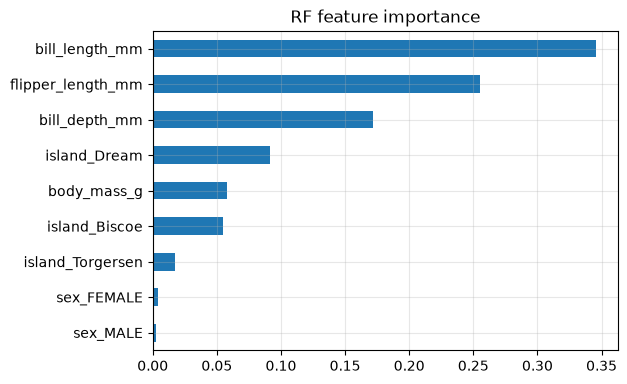

,model,settings,accuracy,precision,recall,f1,f1_std
0,KNN ทุก feature,,0.9913,0.9913,0.9900,0.9904,0.0122
1,KNN top-3 (ANOVA),,0.9594,0.9572,0.9464,0.9504,0.0247


✍️ feature สำคัญสุด 3 อันดับ (RF): ['bill_length_mm', 'flipper_length_mm', 'bill_depth_mm']


In [12]:
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
K_BEST = 3                                     # ✏️ จำนวน feature ที่จะเลือก

Xp = pd.DataFrame(Xtr, columns=names)
const = [c for c in Xp if Xp[c].nunique() <= 1]
print("feature ค่าคงที่:", const or "-")
cm_ = Xp.corr().abs(); upper = cm_.where(np.triu(np.ones(cm_.shape, dtype=bool), 1))
print("คู่ที่ |r| > 0.9:", [(a, b, round(float(upper.loc[a, b]), 3)) for a in upper.index for b in upper.columns if upper.loc[a, b] > 0.9] or "-")

ytr_num = y_train if pd.api.types.is_numeric_dtype(y_train) else LabelEncoder().fit_transform(y_train)
fs = pd.DataFrame({"ANOVA_F": f_classif(Xp, ytr_num)[0],
                   "mutual_info": mutual_info_classif(Xp, ytr_num, random_state=SEED),
                   "RF_importance": RandomForestClassifier(random_state=SEED).fit(Xp, y_train).feature_importances_},
                  index=names).sort_values("RF_importance", ascending=False)
display(fs.round(4))
fs["RF_importance"].plot(kind="barh", figsize=(6, 0.35 * len(fs) + 1), title="RF feature importance"); plt.gca().invert_yaxis(); plt.show()

# CV: ทุก feature vs SelectKBest ใน pipeline (เลือกใหม่ทุก fold → ไม่ leak)
sel_pipe = Pipeline([("prep", build_prep(X)), ("select", SelectKBest(f_classif, k=K_BEST)), ("model", KNeighborsClassifier())])
t = results_table([evaluate("KNN ทุก feature", make_pipe(KNeighborsClassifier(), X), X, y),
                   evaluate(f"KNN top-{K_BEST} (ANOVA)", sel_pipe, X, y)])
print("✍️ feature สำคัญสุด 3 อันดับ (RF):", list(fs.index[:3]))

**✍️ คำตอบ §9:** ตัด … เพราะ … · feature สำคัญสุดคือ … · ใช้ top-… แล้ว F1 … (ดีขึ้น/ใกล้เดิมแต่โมเดลง่ายขึ้น)

## §10 Save ข้อมูลที่ preprocess แล้ว (ถ้าโจทย์ให้ส่งไฟล์)

In [13]:
pd.DataFrame(Xtr, columns=names).assign(**{TARGET: y_train.values}).to_csv("t02_train_preprocessed.csv", index=False)
pd.DataFrame(Xte, columns=names).assign(**{TARGET: y_test.values}).to_csv("t02_test_preprocessed.csv", index=False)
print("saved t02_train_preprocessed.csv, t02_test_preprocessed.csv")

saved t02_train_preprocessed.csv, t02_test_preprocessed.csv
